```{contents}
:local:
:depth: 2
```

# 1.1 Formulating Optimization Problems

```{admonition} Draft status: first draft
:class: warning
First draft (2026-10-30), written from the course design notes. Not yet reviewed.
```

```{admonition} Lectures
:class: tip
This topic accompanies these recorded lessons:

- Module 1, Lesson 1: *Optimization Formulations*
- Module 1, Lesson 2: *Variable and Formulation Types*
- Module 1, Lesson 3: *Optimization Solvers and Quality of Solutions*
```

:::{admonition} Learning Objectives
:class: tip

By the end of this topic, you should be able to:

- Write an engineering decision as an optimization problem with decision variables, an objective, and constraints.
- Classify a formulation by its variable types, its function types, and its convexity.
- Explain what a solver's report of "optimal" does and does not guarantee.
- Recognize that the class of a formulation decides which solvers you are allowed to trust.
:::

If a question starts with "what is the best…", it is probably an optimization problem, whether we are looking for the cheapest way to run a plant, the reactor temperature that gives the highest yield, or the units that should be switched on to meet tomorrow's demand. Although the mathematics of answering these questions is mature and the software is excellent, the software only answers the question that you actually wrote down, so most of the skill in optimization comes from writing the problem down in a way that captures what can be decided, what is being measured, and what cannot be violated. In this topic we will focus on that step, since each of these choices affects how the problem can be solved.

There are three steps in the general approach. To begin with, we need to understand the problem, which includes figuring out the decisions that are available, the goal that we are trying to reach, and the requirements that the answer has to satisfy. Once the problem is understood we can identify its form, i.e. whether the variables are continuous, discrete or both, and whether the equations are linear or nonlinear. The form then dictates the choice of method, which could be a local or a global solver for linear, nonlinear or mixed-integer problems. In practice these steps sit inside a loop: a model is built and optimized, and then we assess whether the optimal solution represents reality or whether it has exploited a gap in the model, in which case we revise the model and go around the loop again.

We can look for the best choice in two different ways. The instinct of a programmer is to **enumerate**, which means looping over every option (or over a grid of values) and keeping the best one. This works for problems with one or two variables, but enumeration misses optima that fall between grid points and becomes impossible in high dimensions. An optimizer instead **formulates** the problem by translating the logic of the goal and the rules into equations, and then hands them to a numerical method that uses derivatives, bounds and proofs to find the optimum systematically (and, when the problem allows, with a guarantee). It turns out that almost any logical rule can be written as equations, and much of this course is about how to do it.

Throughout the first three parts of this book we will work with one example and change it one piece at a time, so it is worth introducing it now.

## A running example: an electrolyzer plant

Hydrogen can be made by splitting water with electricity, $2\,\mathrm{H_2O} \rightarrow 2\,\mathrm{H_2} + \mathrm{O_2}$, in a device called an electrolyzer. A plant typically has several electrolyzer stacks, each of which can be run at any load between off and full capacity. Suppose that a plant has three stacks, A, B, and C, which can each make 200 kg of hydrogen per hour at full load, with a customer demand of 240 kg/h. How should the plant split the work among the three stacks?

The stacks are not identical, since some are older than others or run hotter than others, and each stack turns electricity into hydrogen with a different efficiency at different loads. We will describe a stack by its power curve $P_i(x_i)$, which is the electrical power drawn when the stack runs at a fraction $x_i$ of its full load. The cheapest split is then the one that draws the least total power while still making 240 kg/h.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('../settings/plot_style.mplstyle')
from _lib import electrolyzer as el

print(f"one stack at full load makes {el.KG_H_PER_UNIT:.0f} kg H2/h")
print(f"the ideal (reversible) power for that is {el.MW_PER_UNIT:.2f} MW")

one stack at full load makes 200 kg H2/h
the ideal (reversible) power for that is 6.54 MW


The second number is worth a comment. Splitting one mole of liquid water at room temperature needs at least 237 kJ of work, so making 200 kg/h of hydrogen needs at least 6.5 MW. No real stack achieves this ideal, because the losses inside the stack add to the ideal power. In this book we will measure power in units of this ideal full-load power and load as a fraction of full load, so that a stack running at $x = 1$ with no losses would draw $P = 1$. This per-unit convention is borrowed from power engineering, and keeps the numbers small and comparable. The helper functions `el.to_mw` and `el.to_kg_h` can be used to convert back whenever we want physical units.

:::{exercise}
:label: ex-t11-per-unit

A stack running at full load with ohmic losses draws $P = 1 + r$ per-unit. Convert this to megawatts and to kWh per kilogram of hydrogen for stacks A, B and C, using `el.to_mw` and the 200 kg/h full-load output. How do these compare with the 50–55 kWh/kg typical of commercial electrolyzers?
:::

## Anatomy of a formulation

Every optimization problem contains three ingredients:

1. **Decision variables** are the quantities you are free to choose. Here they are the three loads $x_A$, $x_B$, $x_C$.
2. **An objective function** measures how good a choice is. Here it is the total power, $P_A(x_A) + P_B(x_B) + P_C(x_C)$, which we want to minimize.
3. **Constraints** describe which choices are allowed. Here the loads must add up to the demand, and each load must lie between zero and full capacity.

The picture is completed by two more elements. **Parameters** are the fixed numbers used to build the model, such as the demand $D$ and the loss coefficients of each stack, and their values are given rather than decided. **Bounds** are the simplest type of constraint, consisting of just a lower and an upper limit on a single variable (here $0 \le x_i \le 1$), and solvers handle bounds separately from general constraints because the enforcement of bounds is cheap. Equality constraints are satisfied exactly (e.g. a mass balance or the demand balance), while inequality constraints keep a function of the variables within a limit (e.g. a product purity of at least 90 %, or a load of at most full capacity).

The **degrees of freedom** of a problem are the number of variables minus the number of independent equality constraints. The dispatch problem, for example, has three variables and one equality, giving two degrees of freedom, which means that once two loads are chosen the demand fixes the third. A problem with zero degrees of freedom leaves no room for optimization.

Real models have many similar variables and constraints, and writing them with **indices** is much more convenient than naming each one. For example, instead of naming each load we can write $x_i$ for $i \in I = \{A, B, C\}$, where a constraint written "for all $i \in I$" stands for one constraint per element of the set. The vector $x = (x_A, x_B, x_C)$ collects the loads. We will see in Topic 1.3 that optimization software is also organized around sets and indexed variables.

The full dispatch problem is then

$$
\begin{aligned}
\min_{x_A,\, x_B,\, x_C} \quad & P_A(x_A) + P_B(x_B) + P_C(x_C) \\
\text{s.t.} \quad & x_A + x_B + x_C = D \\
& 0 \le x_i \le 1, \quad i \in \{A, B, C\}
\end{aligned}
$$

with $D = 1.2$ for a demand of 240 kg/h. This is an instance of the standard form that is used by almost every optimization text and solver:

$$
\begin{aligned}
\min_{x} \quad & f(x) \\
\text{s.t.} \quad & g_j(x) \le 0, \quad j = 1, \ldots, m \\
& h_k(x) = 0, \quad k = 1, \ldots, p \\
& x \in X
\end{aligned}
$$

where $f$ is the objective, the $g_j$ are inequality constraints, the $h_k$ are equality constraints, and $X$ defines the allowed values of $x$ (real numbers, integers, or a mix). Two conventions are worth fixing at this point. A maximization problem is a minimization of $-f$, so the problem can always be written with "min", and an inequality in the other direction, $g(x) \ge 0$, is the same as $-g(x) \le 0$. Putting a problem into standard form is mostly bookkeeping, but writing the standard form forces you to say exactly which quantities are decided, measured, and required.

A choice of $x$ that satisfies every constraint is called **feasible**, and the set of all feasible points is the **feasible region**. The job of a solver is to find the feasible point with the smallest objective. In the dispatch problem, any split that adds up to 1.2 and keeps each load between 0 and 1 is feasible, so for example we could run all three stacks at 0.4:

In [2]:
loads = (0.4, 0.4, 0.4)
cost = sum(el.p_ohmic(x, c) for x, c in zip(loads, el.NAMES))
print(f"equal split: total power {cost:.3f} per-unit = {el.to_mw(cost):.2f} MW")

equal split: total power 1.448 per-unit = 9.46 MW


Here we used the ohmic power curve $P_i(x) = x + r_i x^2$, where the losses grow with the square of the load as they do in resistive heating. Whether the equal split is the best one is exactly the question that the optimizer answers.


:::{exercise}
:label: ex-t11-standard-form

Write the dispatch problem in the standard form above. Identify each $f$, $g_j$, $h_k$ and the set $X$, and count the inequality constraints. Then change the demand constraint to "make at least 240 kg/h" and say what changes in the standard form.
:::

## Variable types and formulation types

The same dispatch question can be written in several ways, and the way it is written decides which class of problem it is. The two properties that matter most are the type of the variables and the type of the functions.

In terms of **variable types**, continuous variables can take any real value in a range (e.g. a load or a temperature), while integer variables take whole-number values (e.g. the number of stacks to build). Binary variables are integers restricted to 0 or 1, and they are how optimization models represent yes-or-no decisions such as "is stack B switched on?". If a formulation has both continuous and integer variables, it is called mixed-integer.

An integer variable can always be rewritten with binary variables. If an integer $n$ may take one of the values $a_1, \ldots, a_k$, we can introduce one binary $z_j$ per value, require exactly one of them to be 1, and recover $n$ as a weighted sum:

$$
n = \sum_{j=1}^{k} a_j z_j, \qquad \sum_{j=1}^{k} z_j = 1, \qquad z_j \in \{0, 1\}.
$$

For a range $0, 1, \ldots, 2^K - 1$, a binary expansion $n = \sum_{j=0}^{K-1} 2^j z_j$ needs only $K$ binaries, so the number of stacks to build (between 0 and 3) is $n = z_0 + 2 z_1$. Since mixed-integer solvers are built around binary decisions (Topic 2.5), formulations are often written with only continuous and binary variables.

In terms of **function types**, a problem is called linear when the objective and every constraint are linear functions of the variables, which means that each function is a sum of parameters times variables, $c_1 x_1 + c_2 x_2 + \cdots$. If even one term is nonlinear (e.g. $\sqrt{x}$, $x^2$ or a product of two variables $x \cdot y$), then we call the whole problem nonlinear.

Combining the type of variables with the type of functions gives the four classes used in this course:

| | Continuous variables only | Some integer or binary variables |
|---|---|---|
| **All functions linear** | Linear program (LP) | Mixed-integer linear program (MILP) |
| **Some function nonlinear** | Nonlinear program (NLP) | Mixed-integer nonlinear program (MINLP) |

Two rarer classes complete the picture. If *every* variable is integer, a linear problem is an integer program (IP, or ILP) and a nonlinear one is an integer nonlinear program (INLP). In a MILP every function must be linear in all variables together, so a product of a continuous and a binary variable, $x \cdot y$, makes the problem an MINLP (Topic 2.4 shows how such products are linearized).

The electrolyzer plant can be written in every one of these classes. Each version below keeps the same decision and changes one modeling choice, which is how we describe the power a stack draws. We will treat these choices as dials, and we will turn them one at a time over the first two parts of the book.

| Power curve $P_i(x)$ | Physical idea | Class |
|---|---|---|
| $e_i x$ | every unit of hydrogen costs the same | LP (Topics 1.4, 1.5) |
| $x + r_i x^2$ | resistive losses grow with load | NLP, convex (Topic 2.1) |
| $F_i + e_i x$ when on, 0 when off | a stack costs something just to keep running | MILP (Topics 2.4, 2.5) |
| $x + a_i \frac{x}{x+\epsilon} + r_i x^2$ | efficiency is poor at low load | NLP, non-convex (Topic 2.6) |
| the last curve, plus on/off decisions | all of the above | MINLP (Topic 2.6) |

The last curve exaggerates a real effect. At low current, a noticeable fraction of the current in a real stack does not make hydrogen, so the power needed per kilogram rises sharply at low load. Real stacks are also not allowed to run below a minimum load, which hides most of this effect, but we will keep it visible on purpose since it is the simplest way to show what makes optimization hard.

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


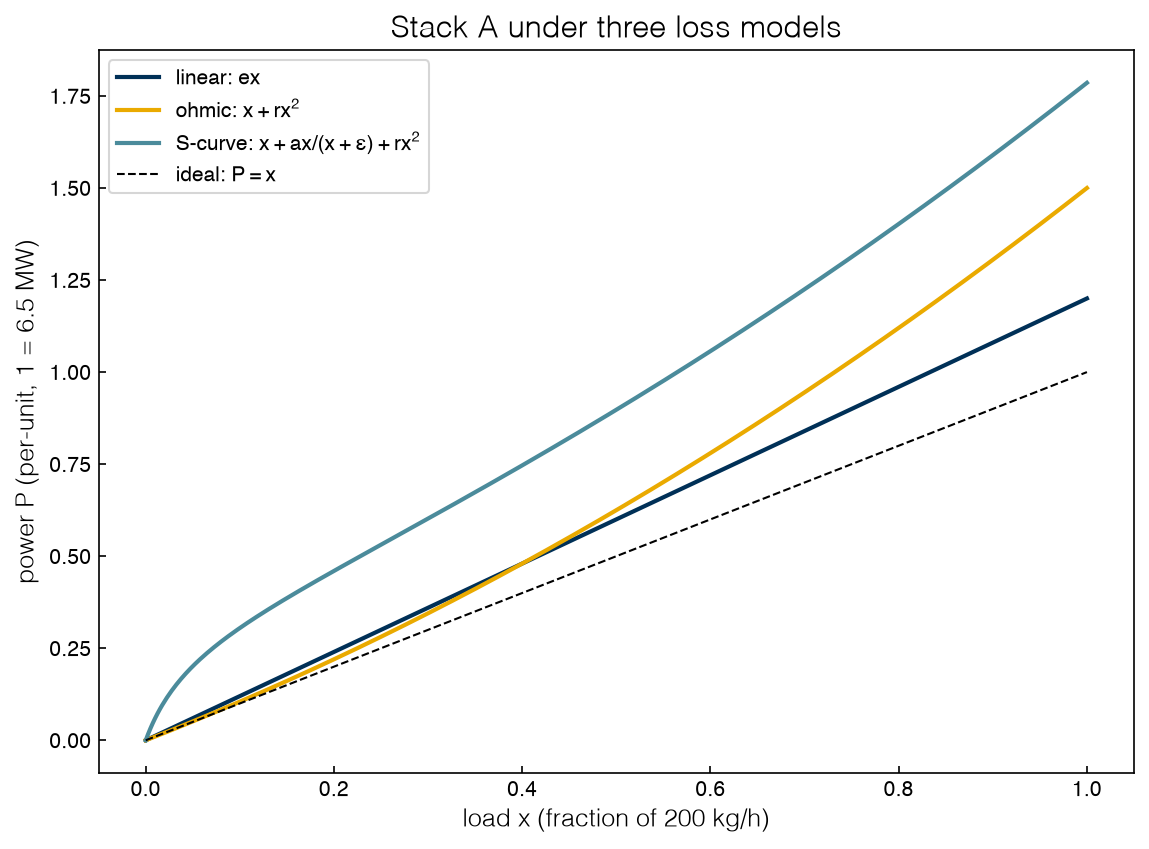

In [3]:
x = np.linspace(0, 1, 400)
fig, ax = plt.subplots()
ax.plot(x, el.p_linear(x, 'A'), label='linear: $e x$')
ax.plot(x, el.p_ohmic(x, 'A'), label='ohmic: $x + r x^2$')
ax.plot(x, el.p_scurve(x, 'A'), label='S-curve: $x + a x/(x+\\epsilon) + r x^2$')
ax.plot(x, x, 'k--', lw=1, label='ideal: $P = x$')
ax.set_xlabel('load $x$ (fraction of 200 kg/h)')
ax.set_ylabel('power $P$ (per-unit, 1 = 6.5 MW)')
ax.set_title('Stack A under three loss models')
ax.legend();

:::{exercise}
:label: ex-t11-classify

For each of the following, name the problem class (LP, NLP, MILP, MINLP): (a) the dispatch problem with linear losses and a rule that each stack runs either at full load or not at all; (b) the dispatch problem with ohmic losses where stacks may be bought in any whole number; (c) the dispatch problem with the S-curve and no on/off decisions. Which of the three are convex?
:::

## Feasible regions and convexity

The variables and functions together decide the shape of the feasible region. With continuous variables it is a region with an interior and a boundary, with only discrete variables it is a collection of separate points, and with nonlinear constraints it can be curved, have holes, or fall apart into disconnected pieces. An inequality constraint is **active** (or binding) at a feasible point if it holds with equality, $g_j(x) = 0$, and it is inactive otherwise. Equality constraints are always active at a feasible point, and the set of constraints that are active at a point is called its **active set**. For example, at the equal split $(0.4, 0.4, 0.4)$ only the demand equality is active, while at the split $(1, 0.2, 0)$ the bounds $x_A \le 1$ and $x_C \ge 0$ are active too. Interior points have no active inequalities. Later on, the active set will tell us where the solutions of LPs sit (Topic 1.4) and which multipliers are nonzero (Topic 2.2).

However, the property of a formulation that matters most is **convexity**, which is even more important than the type of variables or the type of functions.

The definition of convexity is geometric. For a set, convexity means that the straight line between any pair of points in the set stays inside the set, and for a function, convexity means that the straight line between any pair of points on the graph lies on or above the graph. Formally, $f$ is convex when

$$
f(\theta x + (1-\theta) y) \le \theta f(x) + (1-\theta) f(y) \quad \text{for all } x, y \text{ and } 0 \le \theta \le 1 .
$$

An optimization problem is convex when it minimizes a convex function over a convex feasible region. The key property that makes convex problems tractable is that **any local minimum is a global minimum.** In other words, if you are standing at a point where no small move improves the objective, you are at the best point anywhere, which means that a solver with only local information (i.e. most solvers) can be trusted.

Every LP is convex, since linear functions are convex, as are regions defined by linear equalities and inequalities. The ohmic curve is also convex, while the S-curve is not convex because the first term bends the wrong way at low load. Integer variables also destroy convexity, since the set $\{0, 1\}$ has a gap in the middle.

In chemical engineering models, the most common source of non-convexity is the **bilinear term**, which is a product of two variables (e.g. a flowrate times a mole fraction in a component balance, or a flowrate times a temperature in an energy balance). The other common source is a discrete design choice, such as which unit to use for a separation (distillation or a membrane?). A process design model can easily contain both, resulting in a non-convex MINLP, the hardest class. In order of difficulty, LPs are convex and many methods solve them globally, followed by convex NLPs, which can also be solved globally. MILPs are not convex, but their structure lets solvers find and prove global optima routinely. Non-convex NLPs and MINLPs are where a local solver may return only a local solution.

We can see what non-convexity does by looking at the smallest version of the dispatch problem, where two identical stacks of type A share a demand of $D = 0.9$ (180 kg/h). In this case there is only one decision, the load $x_1$ on the first stack, because the second stack must carry $0.9 - x_1$.

ohmic:   best split x1 = 0.449, power 1.1025
S-curve: best split x1 = 0.000, power 1.5892  (equal split gives 1.6425)


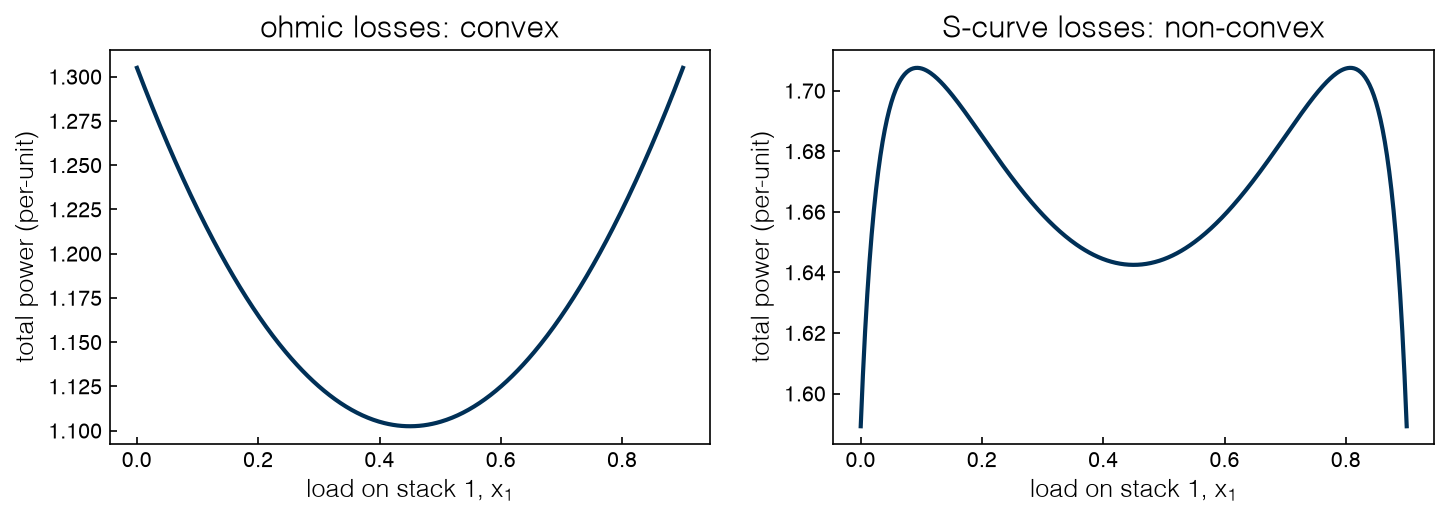

In [4]:
D = 0.9
x1 = np.linspace(0, D, 500)
ohmic = el.p_ohmic(x1, 'A') + el.p_ohmic(D - x1, 'A')
scurve = el.p_scurve(x1, 'A') + el.p_scurve(D - x1, 'A')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(x1, ohmic); axes[0].set_title('ohmic losses: convex')
axes[1].plot(x1, scurve); axes[1].set_title('S-curve losses: non-convex')
for ax in axes:
    ax.set_xlabel('load on stack 1, $x_1$')
    ax.set_ylabel('total power (per-unit)')
plt.tight_layout()
print(f"ohmic:   best split x1 = {x1[np.argmin(ohmic)]:.3f}, power {ohmic.min():.4f}")
print(f"S-curve: best split x1 = {x1[np.argmin(scurve)]:.3f}, power {scurve.min():.4f}"
      f"  (equal split gives {el.bb1([D/2]):.4f})")

With ohmic losses the curve has a single bowl, and the optimal split is the equal one, so two identical stacks should share the load. With the S-curve the equal split is still a valley, but not the lowest one, since a lightly loaded second stack wastes power and the best option is to run one stack alone. As a result, the right-hand plot has two kinds of minimum, corresponding to the operation of one stack alone or to equal sharing between both stacks, and only the first gives the best answer.


:::{exercise}
:label: ex-t11-convexity

Use the definition of convexity to show that $P(x) = x + r x^2$ is convex for $r \ge 0$. Then pick two loads $x$ and $y$ and a value of $\theta$ for which the S-curve of stack A violates the convexity inequality, and check your choice numerically with `el.p_scurve`.
:::

## Optimality and what a solver certifies

A point $x^*$ is called a **global minimum** if no feasible point has a lower objective, and a **local minimum** if no feasible point nearby has a lower objective. Every global minimum is a local minimum, but the reverse is not true, as illustrated by the equal split on the right-hand plot, which is a local minimum but not a global one.

In symbols, with $S$ denoting the feasible region, the definition of a global minimizer $x^*$ is that $f(x^*) \le f(x)$ for all $x \in S$, and the definition of a local minimizer $x^\dagger$ is that there is some $\varepsilon > 0$ such that $f(x^\dagger) \le f(x)$ for all $x \in S$ with $\lVert x - x^\dagger \rVert \le \varepsilon$. For a problem without constraints, a point where all first derivatives of $f$ vanish is a **stationary point**. Every local minimizer of a smooth unconstrained problem is stationary, but a stationary point can also be a maximum or a saddle point, so a zero gradient alone does not prove a minimum (Topic 2.1 adds the second-order test).

How much the difference between local and global matters depends on the application. For example, a protein folds into its global minimum-energy structure, so for structure prediction a local minimum is the wrong answer. In refinery planning, the gap between a local and the global optimum can be worth millions of dollars a year, while in other settings a good local solution is all that is needed.

Most solvers work by starting somewhere and moving downhill until no nearby move helps, at which point they stop at a local minimum and report success. On a convex problem that report is a guarantee, but on a non-convex problem it only tells us about the neighborhood the solver happened to explore. We can see this by starting the same local solver from two different splits:

In [5]:
from scipy.optimize import minimize

for start in (0.45, 0.05):
    res = minimize(lambda z: el.bb1(z), x0=[start], bounds=[(0, D)], method='L-BFGS-B')
    print(f"start x1 = {start:.2f} -> x1 = {res.x[0]:.3f}, power {res.fun:.4f}, "
          f"solver says: {res.message}")

start x1 = 0.45 -> x1 = 0.450, power 1.6425, solver says: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
start x1 = 0.05 -> x1 = 0.000, power 1.5892, solver says: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL


Both runs report convergence, but only one of them found the best answer, and nothing in the output of the first run tells you so. This is something to keep in mind for the rest of the course, since **the class of the problem determines which solvers you are allowed to trust.**

Every optimization method can be thought of as a systematic search that tries values of the variables in an order designed to improve the objective and keeps track of the best feasible point that has been found. Methods differ in the claims that can be made about that point. An **exact** optimal solution is one that is proven to be the best possible, at least within the guarantee the method offers, while a **heuristic** (or approximate) solution is a good feasible point from a method without any guarantees.

Broadly speaking, solvers come in two families. **Deterministic methods** follow a fixed sequence of steps, so the same problem gives the same answer every time, and examples include the simplex method for LPs, gradient-based methods for NLPs, and branch-and-bound for mixed-integer problems. Local deterministic methods guarantee convergence to a local optimum, while global deterministic methods guarantee convergence to a global optimum and can prove that a solution is the best, at a higher computational cost. **Stochastic methods** such as genetic algorithms, simulated annealing, particle swarm optimization and scatter search use randomness to explore, which means two runs on the same problem can return different answers (Topic 3.3). Stochastic methods will often find good solutions on hard problems, although proofs of optimality are rare. A brute-force grid search like the 500-point scan above is the simplest global method of all and works well for one variable, but a grid search becomes hopeless very fast, since a grid of 100 points per variable needs $100^{10}$ evaluations for ten variables.

| Problem class | Typical method | Is "optimal" a guarantee? |
|---|---|---|
| LP | simplex, interior point | yes (convex) |
| Convex NLP | gradient-based local methods | yes |
| Non-convex NLP | local methods | no, only local |
| | global methods (spatial branch-and-bound) | yes, at higher cost |
| MILP | branch-and-bound | yes |
| MINLP | branch-and-bound with local relaxations | no, only local |
| | global MINLP solvers | yes, at higher cost |

The rest of the optimization fundamentals topics build the tools for the convex, continuous classes. We will work through one example of each class in Topic 1.2, introduce the modeling software in Topic 1.3, and treat linear programming in Topics 1.4 and 1.5. After that, Topics 2.1–2.6 turn the dials toward nonlinearity, integers, and non-convexity, and the last of them, Topic 2.6, writes the electrolyzer problem as a full MINLP and solves it with a certificate of global optimality.


:::{exercise}
:label: ex-t11-multistart

Run the local solver from 20 evenly spaced starting loads between 0 and 0.9 on the two-stack S-curve problem. What fraction of the runs find the global minimum? Repeat with the ohmic curve. How would your answer change the advice you give someone who has only a local solver?
:::

## Summary

- An optimization problem has decision variables, an objective, and constraints. Writing them down precisely, in standard form, is most of the work.
- Variable type (continuous, integer, mixed) and function type (linear, nonlinear) sort formulations into LP, NLP, MILP, and MINLP.
- Convexity is the property that matters most: on a convex problem every local minimum is global, so a local solver can be trusted.
- A solver's "optimal" is a guarantee only when the problem class allows it. The same dispatch problem changes class, and difficulty, depending on how we model one physical effect.

## Additional Reading

- A. Ravindran, K. M. Ragsdell and G. V. Reklaitis, *Engineering Optimization: Methods and Applications*, 2nd ed., Wiley (2006). Chapters 1–2 cover formulation and classification.
- D. Bertsimas and J. N. Tsitsiklis, *Introduction to Linear Optimization*, Athena Scientific (1997). The companion MIT OpenCourseWare notes are *Optimization Methods* (15.093J, Fall 2009).
- L. T. Biegler, *Nonlinear Programming: Concepts, Algorithms, and Applications to Chemical Processes*, SIAM (2010). Chapter 1 introduces optimization in chemical engineering.
- S. Boyd and L. Vandenberghe, *Convex Optimization*, Cambridge University Press (2004). Chapters 2–3 on convex sets and functions; freely available from the authors.